# Timestral

**Timestral** is Mistral AI's family of pretrained **time series foundation models** (5M to 209M parameters). Like TimesFM-3, it is **zero-shot**: it is not trained on our data. We pass the history as *context* and it directly outputs the forecast for the requested horizon.

- Context up to **32,768** past points; horizon up to **1,024** steps in a single forward pass.
- Probabilistic: returns **21 quantiles** (0.01 to 0.99) besides the median forecast.
- Runs on standard **CPUs**, no GPU needed.

**Pros:** no training or tuning, small and fast (even on CPU), built-in uncertainty, permissive license (modified MIT).
**Cons:** black box, newer model with less community experience, zero-shot may miss domain-specific patterns.

As with the other models, Timestral predicts only $\hat{Z}_2(t)$ (the log error), and the forecast is rebuilt with $\hat{X}(t) = e^{\hat{Z}_2(t) + (\alpha_0 + \alpha_1 t)}$.

### Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.simplefilter('ignore', ConvergenceWarning)

In [3]:
import time
import math
import scipy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure
from matplotlib import image as mpimg

In [4]:
def transform_date(date):
    try:
        new_date = date.year + (date.month - 1)/12 + date.day/365
        return new_date
    except:
        return float('nan')

In [5]:
def transform_value(value):
    try:
        return float(value)
    except:
        return float('nan')

In [6]:
start = time.time()

# 1. Read DataFrame

In [7]:
df = pd.read_csv('AirPassengers.csv')
df = df.rename(columns = {'Month': 'Time', 'Passengers': 'X_t'})
df['Time'] = pd.to_datetime(df['Time'])
df['Time'] = df['Time'].map(lambda x: transform_date(x))
df['X_t'] = df['X_t'].map(lambda x: transform_value(x))
df = df.dropna()

# 2. Split

In [8]:
train = df[df['Time'] <= 1955]
val = df[(df['Time'] > 1955) & (df['Time'] <= 1958)]
test = df[df['Time'] > 1958]

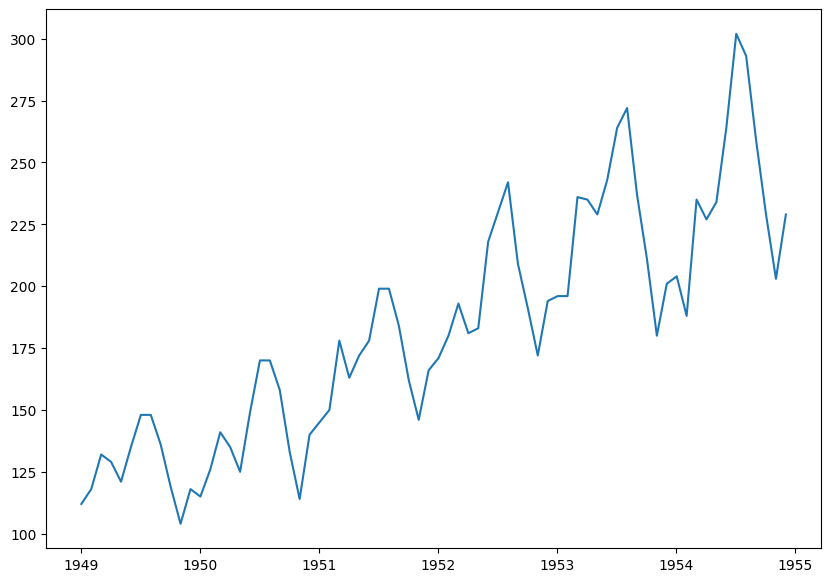

In [9]:
plt.figure(figsize = (10, 7))
plt.plot(train['Time'], train['X_t'])
plt.show()

# 3. Box Cox

In [10]:
train['log_X_t'] = np.log(train['X_t'])
val['log_X_t'] = np.log(val['X_t'])
test['log_X_t'] = np.log(test['X_t'])

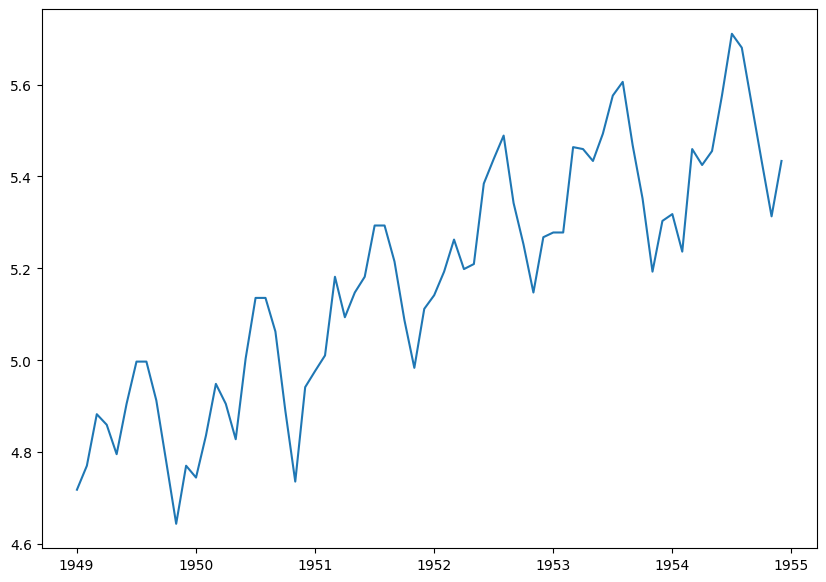

In [11]:
plt.figure(figsize = (10, 7))
plt.plot(train['Time'], train['log_X_t'])
plt.show()

# 4. Exogen Regression

We dont have exogen variables.

# 5. Endogen Regression

We going to use linear trend.

In [12]:
from sklearn.linear_model import LinearRegression

In [13]:
reg = LinearRegression().fit(train[['Time']], train['log_X_t'])

In [14]:
train['log_trend'] = reg.predict(train[['Time']])
val['log_trend'] = reg.predict(val[['Time']])
test['log_trend'] = reg.predict(test[['Time']])

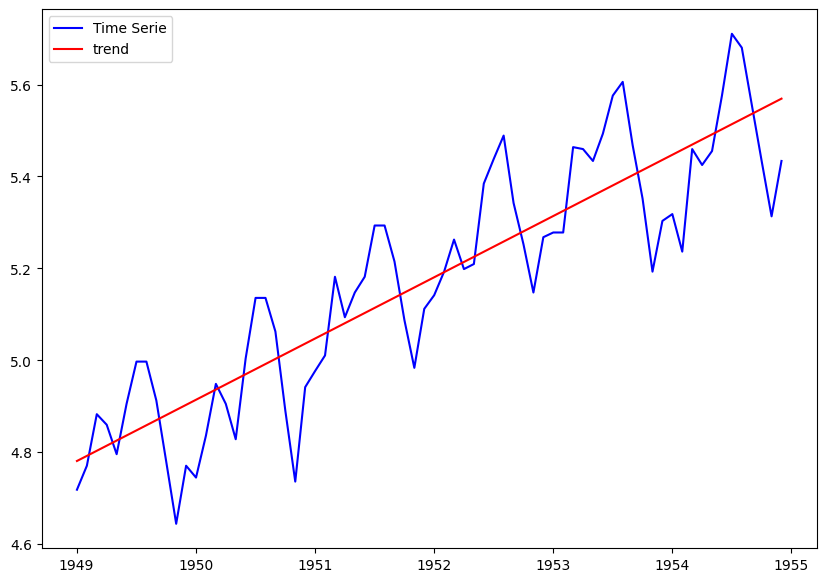

In [15]:
plt.figure(figsize = (10, 7))
plt.plot(train['Time'], train['log_X_t'], color = 'blue', label = 'Time Serie')
plt.plot(train['Time'], train['log_trend'], color = 'red', label = 'trend')
plt.legend()
plt.show()

In [16]:
train['log_error'] = train['log_X_t'] - train['log_trend']
val['log_error'] = val['log_X_t'] - val['log_trend']
test['log_error'] = test['log_X_t'] - test['log_trend']

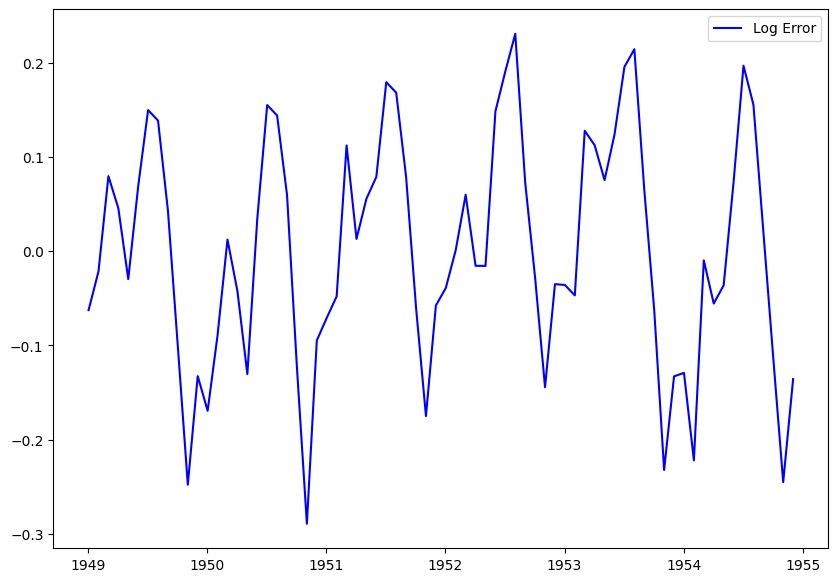

In [17]:
plt.figure(figsize = (10, 7))
plt.plot(train['Time'], train['log_error'], color = 'blue', label = 'Log Error')
plt.legend()
plt.show()

# Evaluation framework

Every model predicts only $\hat{Z}_2(t)$ (the log error). The forecast in the original scale is:

$$\hat{X}(t) = e^{\hat{Z}_2(t) + (\alpha_0 + \alpha_1 t)}$$

We compare models on the validation set with RMSE and MAPE, always in the original scale (passengers).

# 6. Trimestral

In [19]:
import torch
from timestral import TimestralForecaster

model_tst = TimestralForecaster.from_pretrained(
    "mistralai/Timestral-209M",
    device="cuda" if torch.cuda.is_available() else "cpu",
)

Fetching 2 files: 100%|██████████| 2/2 [00:16<00:00,  8.24s/it]


In [20]:
context = train['log_error'].values.astype(np.float32)
horizon = len(val) + len(test)   # 72 months

forecast_tst = model_tst.forecast(context, prediction_length=horizon)

z2_hat_future = np.asarray(forecast_tst.median).ravel()   # shape (72,)
z2_q10 = np.asarray(forecast_tst.quantile(0.1)).ravel()
z2_q90 = np.asarray(forecast_tst.quantile(0.9)).ravel()

z2_hat_val = z2_hat_future[:len(val)]
z2_hat_test = z2_hat_future[len(val):]

In [21]:
MIN_CONTEXT = 24

z2_hat_train = np.full(len(train), np.nan)
for t in range(MIN_CONTEXT, len(context)):
    fc = model_tst.forecast(context[:t], prediction_length=1)
    z2_hat_train[t] = np.asarray(fc.median).ravel()[0]

In [22]:
train['X_hat_tst'] = np.exp(z2_hat_train + train['log_trend'].values)
val['X_hat_tst'] = np.exp(z2_hat_val + val['log_trend'].values)
test['X_hat_tst'] = np.exp(z2_hat_test + test['log_trend'].values)

# 7. Evaluate

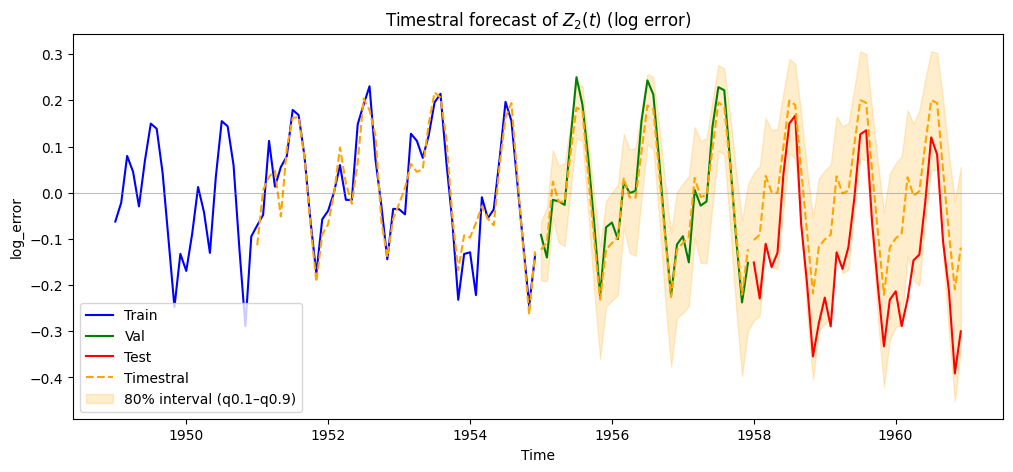

In [23]:
times_future = np.concatenate([val['Time'].values, test['Time'].values])

plt.figure(figsize=(12, 5))
plt.plot(train['Time'], train['log_error'], color='blue', label='Train')
plt.plot(val['Time'], val['log_error'], color='green', label='Val')
plt.plot(test['Time'], test['log_error'], color='red', label='Test')
plt.plot(train['Time'], z2_hat_train, '--', color='orange', label='Timestral')
plt.plot(val['Time'], z2_hat_val, '--', color='orange')
plt.plot(test['Time'], z2_hat_test, '--', color='orange')
plt.fill_between(times_future, z2_q10, z2_q90,
                 color='orange', alpha=0.2, label='80% interval (q0.1–q0.9)')
plt.axhline(0, color='gray', linewidth=0.8, alpha=0.5)
plt.title(r'Timestral forecast of $Z_2(t)$ (log error)')
plt.xlabel('Time'); plt.ylabel('log_error')
plt.legend(); plt.show()

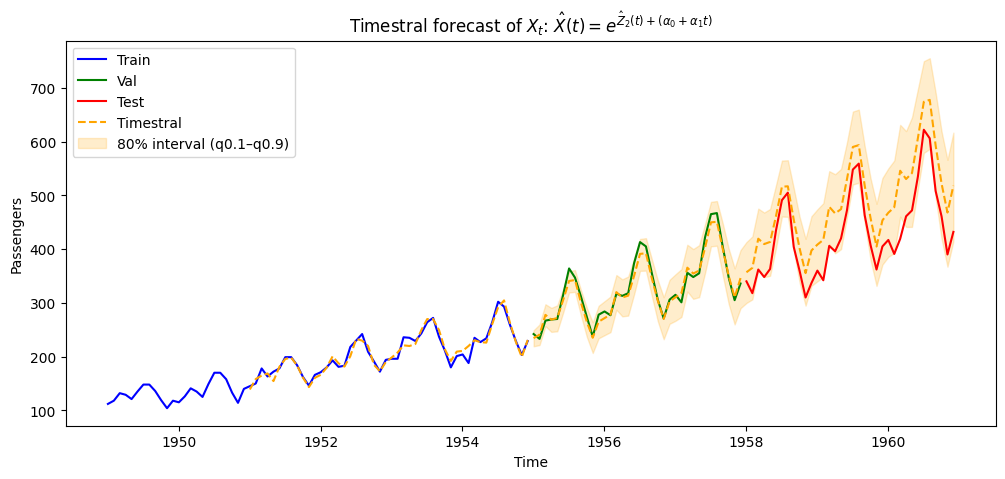

In [24]:
times_future = np.concatenate([val['Time'].values, test['Time'].values])
trend_future = np.concatenate([val['log_trend'].values, test['log_trend'].values])

plt.figure(figsize=(12, 5))
plt.plot(train['Time'], train['X_t'], color='blue', label='Train')
plt.plot(val['Time'], val['X_t'], color='green', label='Val')
plt.plot(test['Time'], test['X_t'], color='red', label='Test')
plt.plot(train['Time'], train['X_hat_tst'], '--', color='orange', label='Timestral')
plt.plot(val['Time'], val['X_hat_tst'], '--', color='orange')
plt.plot(test['Time'], test['X_hat_tst'], '--', color='orange')
plt.fill_between(times_future,
                 np.exp(z2_q10 + trend_future),
                 np.exp(z2_q90 + trend_future),
                 color='orange', alpha=0.2, label='80% interval (q0.1–q0.9)')
plt.title(r'Timestral forecast of $X_t$: $\hat{X}(t) = e^{\hat{Z}_2(t) + (\alpha_0 + \alpha_1 t)}$')
plt.xlabel('Time'); plt.ylabel('Passengers')
plt.legend(); plt.show()

In [25]:
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                             mean_absolute_percentage_error, r2_score)

def performance(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    mask = ~np.isnan(y_pred)   # skip months without prediction (first MIN_CONTEXT of train)
    y_true, y_pred = y_true[mask], y_pred[mask]
    return {
        'RMSE': mean_squared_error(y_true, y_pred) ** 0.5,
        'MAE': mean_absolute_error(y_true, y_pred),
        'MAPE (%)': mean_absolute_percentage_error(y_true, y_pred) * 100,
        'R2': r2_score(y_true, y_pred),
    }

rows = [
    {'Scale': 'log_error', 'Set': 'train', **performance(train['log_error'], z2_hat_train)},
    {'Scale': 'log_error', 'Set': 'val',   **performance(val['log_error'], z2_hat_val)},
    {'Scale': 'log_error', 'Set': 'test',  **performance(test['log_error'], z2_hat_test)},
    {'Scale': 'X_t',       'Set': 'train', **performance(train['X_t'], train['X_hat_tst'])},
    {'Scale': 'X_t',       'Set': 'val',   **performance(val['X_t'], val['X_hat_tst'])},
    {'Scale': 'X_t',       'Set': 'test',  **performance(test['X_t'], test['X_hat_tst'])},
]

metrics_tst_df = pd.DataFrame(rows).set_index(['Scale', 'Set']).round(4)
metrics_tst_df

RMSE      MAE  MAPE (%)      R2
Scale     Set                                      
log_error train   0.0447   0.0336   58.7230  0.8663
          val     0.0317   0.0262   90.4331  0.9463
          test    0.1359   0.1273  121.6929  0.1730
X_t       train   9.0534   6.8728    3.3715  0.9399
          val    10.9158   8.7757    2.5938  0.9655
          test   60.9947  57.0646   13.7017  0.3919